In [21]:
from langgraph.graph import StateGraph, MessagesState, START, END
from typing import TypedDict


In [22]:
#State
class BMIState(TypedDict):
    weight : float
    height : float
    bmi : float
    category : str

In [23]:
def calcBMI(state : BMIState):
    state['bmi'] = state['weight'] / (state['height'] ** 2)
    return state


In [24]:
def labelBMI(state : BMIState):
    bmi = state['bmi']
    if bmi < 18.5:
        state['category'] = 'Underweight'
    elif bmi < 25:
        state['category'] = 'Normal weight'
    elif bmi < 30:
        state['category'] = 'Overweight'
    else:
        state['category'] = 'Obesity'
    return state

In [25]:
graph = StateGraph(BMIState)
graph.add_node( "calcBMI", calcBMI )
graph.add_node("labelBMI", labelBMI)
graph.add_edge(START, "calcBMI")
graph.add_edge("calcBMI", "labelBMI")
graph.add_edge("labelBMI", END)
workflow = graph.compile()


In [26]:
final_state = workflow.invoke({ "weight": 70, "height": 1.75 })
print(final_state)

{'weight': 70, 'height': 1.75, 'bmi': 22.857142857142858, 'category': 'Normal weight'}


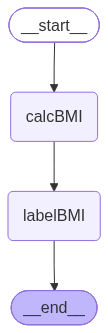

In [27]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())